In [21]:
import cv2
import os
import glob
import numpy as np
from tqdm import tqdm
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from ultralytics import YOLO
import matplotlib.pyplot as plt

# 路径设置
VIDEO_PATH = "E:/course/bishe/daima/cv"
MODEL_SAVE_PATH = "E:/course/bishe/daima/saved_model"
YOLO_MODEL_PATH = "E:/course/bishe/daima/yolov8n.pt"  # 需要下载手部检测的 YOLO 模型

# 定义参数
IMG_SIZE = 224
MAX_SEQUENCE_LENGTH = 40
NUM_FEATURES = 2048  # 让它和 InceptionV3 输出的特征维度匹配
  # InceptionV3 提取的特征维度
BATCH_SIZE = 16
EPOCHS = 100

# 定义手势类别
label_to_name = {
    0: "无效手势", 1: "上滑", 2: "下滑", 3: "左滑", 4: "右滑", 
    5: "打开", 6: "关闭", 7: "放大", 8: "缩小"
}

# 加载 YOLO 模型
yolo_model = YOLO(YOLO_MODEL_PATH)




In [22]:
# **1. 视频预处理（OpenCV 读取 & YOLO 分割）**
def preprocess_video(video_path):
    cap = cv2.VideoCapture(video_path)
    frames = []
    frame_interval = 4  # 每 4 帧抽取 1 帧
    count = 0

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        if count % frame_interval == 0:
            # 进行手部检测，添加 verbose=False 隐藏输出
            results = yolo_model(frame, verbose=False)  # 修改此处
            for result in results:
                for box in result.boxes:
                    x1, y1, x2, y2 = map(int, box.xyxy[0])  # 获取检测框坐标
                    hand_crop = frame[y1:y2, x1:x2]  # 裁剪手部区域

                    # 处理手势图片
                    if hand_crop.size != 0:
                        hand_crop = cv2.resize(hand_crop, (IMG_SIZE, IMG_SIZE))
                        frames.append(hand_crop)

        count += 1

    cap.release()
    return np.array(frames)


In [23]:
# **2. 提取视频特征**
def extract_features(frames):
    base_model = keras.applications.InceptionV3(
        weights="imagenet", include_top=False, pooling="avg", input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    
    features = base_model.predict(frames)
    return features[:MAX_SEQUENCE_LENGTH]  # 截取或补零填充

In [25]:
# **3. 加载数据**
def load_data(video_files, labels):
    video_features = []
    video_labels = []

    for video, label in zip(video_files, labels):
        frames = preprocess_video(video)
        if len(frames) == 0:
            continue

        features = extract_features(frames)
        if features.shape[0] < MAX_SEQUENCE_LENGTH:
            padding = np.zeros((MAX_SEQUENCE_LENGTH - features.shape[0], NUM_FEATURES))
            features = np.vstack((features, padding))

        video_features.append(features)
        video_labels.append(label)

    return np.array(video_features), np.array(video_labels)

In [26]:
# **4. Transformer 模型**
class TransformerEncoder(layers.Layer):
    def __init__(self, num_heads, embed_dim):
        super().__init__()
        self.attention = layers.MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim)
        self.layernorm = layers.LayerNormalization()
    
    def call(self, x):
        attention_out = self.attention(x, x)
        return self.layernorm(x + attention_out)

def create_model(num_classes):
    model = keras.Sequential([
        layers.InputLayer(input_shape=(MAX_SEQUENCE_LENGTH, NUM_FEATURES)),
        TransformerEncoder(num_heads=2, embed_dim=NUM_FEATURES),
        layers.GlobalMaxPooling1D(),
        layers.Dense(1024, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation="softmax")
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


In [27]:
def train_model():
    # 获取所有视频文件
    video_files = glob.glob(os.path.join(VIDEO_PATH, "*.mp4"))
    np.random.shuffle(video_files)

    # 解析标签
    labels = [int(video.split("_")[-2]) for video in video_files]

    # 加载数据
    video_features, video_labels = load_data(video_files, labels)

    # 划分训练集和测试集
    split_idx = int(len(video_files) * 0.8)
    train_x, test_x = video_features[:split_idx], video_features[split_idx:]
    train_y, test_y = video_labels[:split_idx], video_labels[split_idx:]

    # 创建数据集
    train_dataset = tf.data.Dataset.from_tensor_slices((train_x, train_y)).shuffle(len(train_x)).batch(BATCH_SIZE)
    test_dataset = tf.data.Dataset.from_tensor_slices((test_x, test_y)).batch(BATCH_SIZE)

    # 创建模型
    model = create_model(len(label_to_name))

    # 训练
    history = model.fit(train_dataset, validation_data=test_dataset, epochs=EPOCHS, batch_size=BATCH_SIZE)

    # 保存模型
    model.save(MODEL_SAVE_PATH)
    print("模型已保存！")

    # 绘制损失曲线
    plt.plot(history.history['loss'], label='训练损失')
    plt.plot(history.history['val_loss'], label='验证损失')
    plt.legend()
    plt.show()

    # 绘制损失曲线
    plt.plot(history.history['loss'], label='训练损失')
    plt.plot(history.history['val_loss'], label='验证损失')
    plt.legend()
    plt.show()

In [28]:
# **6. 预测**
def predict_video(video_path, model):
    frames = preprocess_video(video_path)
    if len(frames) == 0:
        print("未检测到手势！")
        return

    features = extract_features(frames)
    if features.shape[0] < MAX_SEQUENCE_LENGTH:
        padding = np.zeros((MAX_SEQUENCE_LENGTH - features.shape[0], NUM_FEATURES))
        features = np.vstack((features, padding))

    features = np.expand_dims(features, axis=0)
    predictions = model.predict(features)
    
    top_3 = np.argsort(predictions[0])[-3:][::-1]
    print("预测类别：")
    for idx in top_3:
        print(f"{label_to_name[idx]}: {predictions[0][idx]*100:.2f}%")

3/3 [==============================] - 4s 994ms/step
Epoch 1/100
6/6 [==============================] - 6s 933ms/step - loss: 8.6187 - accuracy: 0.1163 - val_loss: 8.6990 - val_accuracy: 0.0909
Epoch 2/100
6/6 [==============================] - 6s 1s/step - loss: 6.0252 - accuracy: 0.1279 - val_loss: 2.8967 - val_accuracy: 0.0909
Epoch 3/100
6/6 [==============================] - 6s 913ms/step - loss: 2.7913 - accuracy: 0.1744 - val_loss: 2.9968 - val_accuracy: 0.2727
Epoch 4/100
6/6 [==============================] - 6s 939ms/step - loss: 2.8643 - accuracy: 0.1977 - val_loss: 2.1072 - val_accuracy: 0.2273
Epoch 5/100
6/6 [==============================] - 6s 913ms/step - loss: 2.5257 - accuracy: 0.2907 - val_loss: 2.3935 - val_accuracy: 0.0909
Epoch 6/100
6/6 [==============================] - 6s 936ms/step - loss: 2.9775 - accuracy: 0.1279 - val_loss: 2.1025 - val_accuracy: 0.2727
Epoch 7/100
6/6 [==============================] - 5s 921ms/step - loss: 2.4570 - accuracy: 0.2674 - val

INFO:tensorflow:Assets written to: E:/course/bishe/daima/saved_model\assets


模型已保存！


c:\Users\73671\.conda\envs\bs\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 35757 (\N{CJK UNIFIED IDEOGRAPH-8BAD}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\73671\.conda\envs\bs\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 32451 (\N{CJK UNIFIED IDEOGRAPH-7EC3}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\73671\.conda\envs\bs\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 25439 (\N{CJK UNIFIED IDEOGRAPH-635F}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\73671\.conda\envs\bs\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 22833 (\N{CJK UNIFIED IDEOGRAPH-5931}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\73671\.conda\envs\bs\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 39564 (\N{CJK UNIFIED IDEOGRAPH-9A8C}) missing from current font.
  fig.c

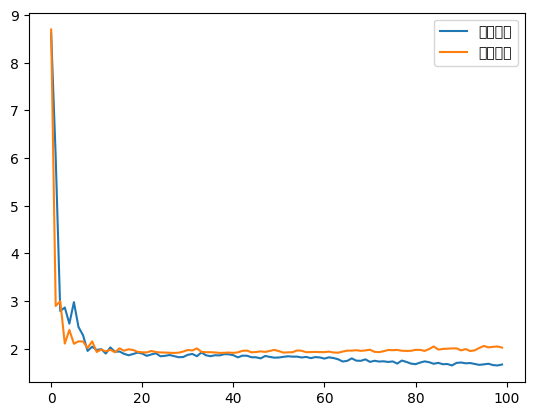

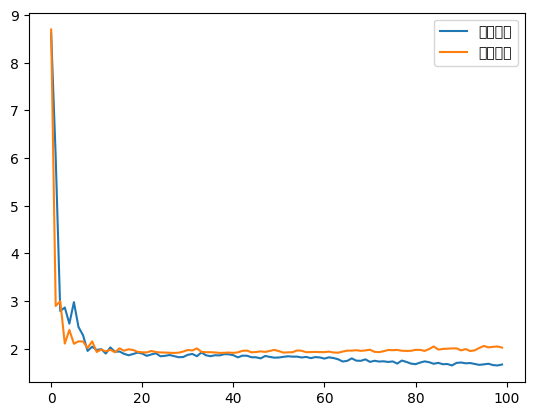

In [38]:
# **7. 测试所有视频**
if __name__ == "__main__":
    train_model()  # 训练模型
    


In [29]:
# 主程序
if __name__ == "__main__":
    # 加载已训练好的模型
    model = keras.models.load_model(MODEL_SAVE_PATH)
    
    # 获取所有测试视频
    test_videos = glob.glob(os.path.join(VIDEO_PATH, "*.mp4"))
    
    # 初始化结果列表
    result_data = []
    
    # 遍历所有视频进行预测
    for video_path in test_videos:
        video_name = os.path.basename(video_path)
        pred_class = predict_video(video_path, model)
        if pred_class is not None:
            result_data.append([video_name, pred_class])
    
    # 保存结果到CSV
    os.makedirs(CSV_SAVE_PATH, exist_ok=True)  # 创建保存目录
    df = pd.DataFrame(result_data, columns=["name", "预测类别"])
    df.to_csv(os.path.join(CSV_SAVE_PATH, "validation_results.csv"), index=False)
    
    print(f"验证完成，结果已保存到：{CSV_SAVE_PATH}/validation_results.csv")

1/1 [==============================] - 0s 94ms/step
预测类别：
无效手势: 99.92%
上滑: 0.07%
打开: 0.00%
1/1 [==============================] - 0s 43ms/step
预测类别：
无效手势: 99.91%
上滑: 0.08%
打开: 0.00%
1/1 [==============================] - 0s 42ms/step
预测类别：
无效手势: 78.44%
上滑: 11.97%
右滑: 2.74%
1/1 [==============================] - 0s 41ms/step
预测类别：
无效手势: 99.92%
上滑: 0.07%
打开: 0.00%
1/1 [==============================] - 0s 42ms/step
预测类别：
无效手势: 99.82%
上滑: 0.16%
打开: 0.01%
1/1 [==============================] - 0s 53ms/step
预测类别：
无效手势: 99.46%
上滑: 0.46%
打开: 0.02%
1/1 [==============================] - 0s 54ms/step
预测类别：
无效手势: 19.12%
左滑: 17.10%
打开: 15.90%
1/1 [==============================] - 0s 51ms/step
预测类别：
无效手势: 16.02%
关闭: 14.86%
左滑: 14.60%
1/1 [==============================] - 0s 48ms/step
预测类别：
无效手势: 99.92%
上滑: 0.08%
打开: 0.00%
1/1 [==============================] - 0s 47ms/step
预测类别：
无效手势: 99.87%
上滑: 0.12%
打开: 0.00%
1/1 [==============================] - 0s 53ms/step
预测类别：
无效手势: 31.60%
上滑: 21.10%
右滑:

NameError: name 'CSV_SAVE_PATH' is not defined